# Lunar aquarium brightness screening — Bocas 2026

Screen two independent, single-camera aquarium recordings for brightness changes. Each Box folder contains 146 sequential 30-minute MP4 files named `part0001` through `part0146`. The files have no embedded recording timestamps, so this notebook assigns approximate Panama times from the shared start estimate: **2026-08-21 18:44** (lights off).

Videos are sorted numerically by part number, downloaded one at a time, scanned over the full frame, and deleted. Per-video CSVs are retained so processing can resume. CamA and cam1 are separate aquariums and are plotted separately.

In [1]:
DATASETS = [
    {
        "key": "aquarium_cam0",
        "label": "Aquarium CamA / cam0",
        "box_url": "https://ucsb.box.com/s/39fao2b54q7zyxun9cgpdewb12catla6",
        "expected_video_count": 146,
        "verified_size_GB": 4.228,
    },
    {
        "key": "aquarium_cam1",
        "label": "Aquarium cam1",
        "box_url": "https://ucsb.box.com/s/zk01itdydmulbu4wgwlsqeiw1pdrqmad",
        "expected_video_count": 146,
        "verified_size_GB": 4.106,
    },
]

TIMEZONE = "America/Panama"
RECORDING_START_PANAMA = "2026-08-21 18:44:00"  # approximate; lights-off time
SEGMENT_DURATION_MINUTES = 30
BATCH_START = 0
BATCH_SIZE = 146  # process the full sequence; reduce for a test run
FRAME_STEP = 5   # 10 fps video -> two measurements per second
MAX_WIDTH = 640   # downscale the full 1280 px frame for screening speed
TOP_FRACTION = 0.001
PERCENTILE = 99.9
BRIGHT_THRESHOLD = 200
FORCE_REPROCESS = False
MEAN_Y_AXIS_MAX = 0.05
BRIGHT_Y_AXIS_MAX = 50

In [2]:
import importlib.util
import json
import re
import sys
import tempfile
import time
import urllib.error
import urllib.parse
import urllib.request
from pathlib import Path
from zoneinfo import ZoneInfo

import cv2
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "scripts" / "brightnessOverTime.py").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
SCRIPT_PATH = PROJECT_ROOT / "scripts" / "brightnessOverTime.py"
RESULTS_ROOT = PROJECT_ROOT / "data" / "processed" / "lunar_brightness_parts"
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)

spec = importlib.util.spec_from_file_location("brightness_over_time", SCRIPT_PATH)
brightness = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = brightness
spec.loader.exec_module(brightness)
local_zone = ZoneInfo(TIMEZONE)
recording_start = pd.Timestamp(RECORDING_START_PANAMA, tz=TIMEZONE)
print(f"Approximate shared recording start: {recording_start}")

Approximate shared recording start: 2026-08-21 18:44:00-05:00


In [7]:
BOX_DATA_RE = re.compile(r"Box\.(?:postStreamData|prefetchedData)\s*=\s*(\{.*?\});", re.DOTALL)
PART_RE = re.compile(r"part(?P<part>\d+)", re.IGNORECASE)
VIDEO_EXTENSIONS = {"avi", "m4v", "mkv", "mov", "mp4", "mpg", "mpeg"}

def _read_url(url, attempts=4):
    headers = {"User-Agent": "Mozilla/5.0", "Accept": "text/html,application/xhtml+xml"}
    for attempt in range(1, attempts + 1):
        try:
            request = urllib.request.Request(url, headers=headers)
            with urllib.request.urlopen(request, timeout=60) as response:
                return response.read().decode("utf-8")
        except (urllib.error.HTTPError, urllib.error.URLError, TimeoutError) as error:
            if attempt == attempts:
                raise RuntimeError(f"Box request failed after {attempts} attempts: {url}") from error
            wait = 2 ** (attempt - 1)
            print(f"Box request failed ({error}); retrying in {wait} seconds...")
            time.sleep(wait)

def parse_part_number(filename):
    match = PART_RE.search(filename)
    if not match:
        raise ValueError(f"No part number found in {filename!r}")
    return int(match.group("part"))

def list_box_videos(shared_url):
    rows, page = [], 1
    while True:
        html = _read_url(f"{shared_url}{'&' if '?' in shared_url else '?'}page={page}")
        candidates = [json.loads(match.group(1)) for match in BOX_DATA_RE.finditer(html)]
        post_data = next((data for data in candidates
                          if "/app-api/enduserapp/shared-folder" in data), None)
        if post_data is None:
            raise RuntimeError("Could not find Box folder metadata. Check that the link is public.")
        folder = post_data["/app-api/enduserapp/shared-folder"]
        rows.extend({"id": int(item["id"]), "name": item["name"],
                     "size_bytes": int(item["itemSize"])}
                    for item in folder["items"]
                    if item.get("type") == "file"
                    and item.get("extension", "").lower() in VIDEO_EXTENSIONS)
        if page >= int(folder["pageCount"]):
            break
        page += 1
    shared_name = post_data["/app-api/enduserapp/shared-item"]["sharedName"]
    table = pd.DataFrame(rows).drop_duplicates("id")
    table["part_number"] = table["name"].map(parse_part_number)
    if table["part_number"].duplicated().any():
        raise RuntimeError("Duplicate part numbers found in Box folder")
    table = table.sort_values("part_number").reset_index(drop=True)
    expected_parts = set(range(table["part_number"].min(), table["part_number"].max() + 1))
    missing_parts = sorted(expected_parts - set(table["part_number"]))
    if missing_parts:
        raise RuntimeError(f"Missing sequential parts: {missing_parts}")
    table["size_GB"] = table["size_bytes"] / 1e9
    table["start_panama_approx"] = recording_start + pd.to_timedelta(
        (table["part_number"] - table["part_number"].min()) * SEGMENT_DURATION_MINUTES, unit="min"
    )
    table["start_utc_approx"] = table["start_panama_approx"].dt.tz_convert("UTC")
    return table, shared_name

def download_box_file(shared_name, file_id, destination, block_size=8 * 1024 * 1024):
    query = urllib.parse.urlencode({"rm": "box_download_shared_file",
                                    "shared_name": shared_name, "file_id": f"f_{file_id}"})
    request = urllib.request.Request(f"https://ucsb.app.box.com/index.php?{query}",
                                     headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(request, timeout=120) as response, destination.open("wb") as output:
        total, downloaded = int(response.headers.get("Content-Length", 0)), 0
        while block := response.read(block_size):
            output.write(block)
            downloaded += len(block)
            if total:
                print(f"\rDownloaded {downloaded / total:6.1%}", end="")
    print()

def scan_full_frame_with_progress(path, start_utc):
    capture = cv2.VideoCapture(str(path))
    if not capture.isOpened():
        raise RuntimeError(f"OpenCV could not open {path.name}")
    fps = float(capture.get(cv2.CAP_PROP_FPS))
    total_frames = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
    if not np.isfinite(fps) or fps <= 0:
        capture.release()
        raise RuntimeError(f"No usable frame rate in {path.name}")
    rows, frame_number = [], 0
    try:
        while True:
            ok, frame = capture.read()
            if not ok:
                break
            if frame_number % FRAME_STEP == 0:
                gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
                gray = brightness.resize_for_screening(gray, MAX_WIDTH)
                mean, top_mean, pct, maximum, bright_fraction = brightness.brightness_metrics(
                    gray, TOP_FRACTION, PERCENTILE, BRIGHT_THRESHOLD
                )
                seconds = frame_number / fps
                time_utc = start_utc + pd.Timedelta(seconds=seconds)
                rows.append(brightness.Measurement(
                    path.name, frame_number, seconds, time_utc.to_pydatetime(),
                    time_utc.tz_convert(TIMEZONE).to_pydatetime(), mean, top_mean, pct,
                    maximum, bright_fraction,
                ))
            frame_number += 1
            if frame_number % 5000 == 0 or frame_number == total_frames:
                print(f"\rAnalyzed {frame_number:,}/{total_frames:,} frames", end="")
    finally:
        capture.release()
    print()
    return rows

## List and validate the sequential recordings

This reads only the Box listing pages. It verifies unique, gap-free part numbers and shows the approximate clock time assigned to each part.

In [8]:
dataset_runs = {}
for config in DATASETS:
    videos, shared_name = list_box_videos(config["box_url"])
    selected = videos.iloc[BATCH_START:BATCH_START + BATCH_SIZE].copy()
    results_dir = RESULTS_ROOT / config["key"]
    results_dir.mkdir(parents=True, exist_ok=True)
    selected["result_exists"] = selected["name"].map(
        lambda name: (results_dir / f"{Path(name).stem}_brightness.csv").exists()
    )
    dataset_runs[config["key"]] = dict(
        config=config, videos=videos, selected=selected, shared_name=shared_name, results_dir=results_dir
    )
    count_status = "matches" if len(videos) == config["expected_video_count"] else "DOES NOT MATCH"
    print(f"\n{config['label']}")
    print(f"Found {len(videos)} videos ({videos['size_GB'].sum():.3f} GB); {count_status} expected count")
    print(f"Part range: {videos['part_number'].min():04d}–{videos['part_number'].max():04d}")
    display(selected[["part_number", "name", "size_GB", "start_panama_approx", "result_exists"]]
            .style.format({"size_GB": "{:.3f}"}))


Aquarium CamA / cam0
Found 146 videos (4.228 GB); matches expected count
Part range: 0001–0146


,part_number,name,size_GB,start_panama_approx,result_exists
0,1,test_cam0_Arducam_B0496_USB3_2MP_part0001.mp4,0.721,2026-08-21 18:44:00-05:00,True
1,2,test_cam0_Arducam_B0496_USB3_2MP_part0002.mp4,0.023,2026-08-21 19:14:00-05:00,True
2,3,test_cam0_Arducam_B0496_USB3_2MP_part0003.mp4,0.023,2026-08-21 19:44:00-05:00,True
3,4,test_cam0_Arducam_B0496_USB3_2MP_part0004.mp4,0.023,2026-08-21 20:14:00-05:00,True
4,5,test_cam0_Arducam_B0496_USB3_2MP_part0005.mp4,0.023,2026-08-21 20:44:00-05:00,True
5,6,test_cam0_Arducam_B0496_USB3_2MP_part0006.mp4,0.023,2026-08-21 21:14:00-05:00,True
6,7,test_cam0_Arducam_B0496_USB3_2MP_part0007.mp4,0.023,2026-08-21 21:44:00-05:00,True
7,8,test_cam0_Arducam_B0496_USB3_2MP_part0008.mp4,0.023,2026-08-21 22:14:00-05:00,True
8,9,test_cam0_Arducam_B0496_USB3_2MP_part0009.mp4,0.023,2026-08-21 22:44:00-05:00,True
9,10,test_cam0_Arducam_B0496_USB3_2MP_part0010.mp4,0.023,2026-08-21 23:14:00-05:00,True



Aquarium cam1
Found 146 videos (4.106 GB); matches expected count
Part range: 0001–0146


,part_number,name,size_GB,start_panama_approx,result_exists
0,1,test_cam1_Arducam_B0496_USB3_2MP_part0001.mp4,0.625,2026-08-21 18:44:00-05:00,True
1,2,test_cam1_Arducam_B0496_USB3_2MP_part0002.mp4,0.023,2026-08-21 19:14:00-05:00,True
2,3,test_cam1_Arducam_B0496_USB3_2MP_part0003.mp4,0.023,2026-08-21 19:44:00-05:00,True
3,4,test_cam1_Arducam_B0496_USB3_2MP_part0004.mp4,0.023,2026-08-21 20:14:00-05:00,True
4,5,test_cam1_Arducam_B0496_USB3_2MP_part0005.mp4,0.023,2026-08-21 20:44:00-05:00,True
5,6,test_cam1_Arducam_B0496_USB3_2MP_part0006.mp4,0.023,2026-08-21 21:14:00-05:00,True
6,7,test_cam1_Arducam_B0496_USB3_2MP_part0007.mp4,0.023,2026-08-21 21:44:00-05:00,True
7,8,test_cam1_Arducam_B0496_USB3_2MP_part0008.mp4,0.023,2026-08-21 22:14:00-05:00,True
8,9,test_cam1_Arducam_B0496_USB3_2MP_part0009.mp4,0.023,2026-08-21 22:44:00-05:00,True
9,10,test_cam1_Arducam_B0496_USB3_2MP_part0010.mp4,0.023,2026-08-21 23:14:00-05:00,True


## Process both aquariums

Each video is downloaded, analyzed over the full frame, and removed before the next download. Completed CSVs are skipped. Progress reports download percentage, analyzed frames, and completed videos.

In [9]:
for dataset_key, run in dataset_runs.items():
    selected = run["selected"]
    total_videos = len(selected)
    print(f"\n=== {run['config']['label']} ===")
    for video_number, item in enumerate(selected.itertuples(index=False), start=1):
        result_path = run["results_dir"] / f"{Path(item.name).stem}_brightness.csv"
        if result_path.exists() and not FORCE_REPROCESS:
            print(f"Skipping completed part {item.part_number:04d}: {item.name}")
            print(f"Completed {video_number} of {total_videos} videos")
            continue
        print(f"\nVideo {video_number} of {total_videos}: part {item.part_number:04d}, {item.name}")
        with tempfile.TemporaryDirectory(prefix=f"lunar_{dataset_key}_") as temp_dir:
            local_video = Path(temp_dir) / item.name
            download_box_file(run["shared_name"], item.id, local_video)
            rows = scan_full_frame_with_progress(local_video, item.start_utc_approx)
            brightness.write_csv(rows, result_path)
            print(f"Saved {len(rows):,} measurements to {result_path.name}")
        print("Deleted the temporary video.")
        print(f"Completed {video_number} of {total_videos} videos")


=== Aquarium CamA / cam0 ===
Skipping completed part 0001: test_cam0_Arducam_B0496_USB3_2MP_part0001.mp4
Completed 1 of 146 videos
Skipping completed part 0002: test_cam0_Arducam_B0496_USB3_2MP_part0002.mp4
Completed 2 of 146 videos
Skipping completed part 0003: test_cam0_Arducam_B0496_USB3_2MP_part0003.mp4
Completed 3 of 146 videos
Skipping completed part 0004: test_cam0_Arducam_B0496_USB3_2MP_part0004.mp4
Completed 4 of 146 videos
Skipping completed part 0005: test_cam0_Arducam_B0496_USB3_2MP_part0005.mp4
Completed 5 of 146 videos
Skipping completed part 0006: test_cam0_Arducam_B0496_USB3_2MP_part0006.mp4
Completed 6 of 146 videos
Skipping completed part 0007: test_cam0_Arducam_B0496_USB3_2MP_part0007.mp4
Completed 7 of 146 videos
Skipping completed part 0008: test_cam0_Arducam_B0496_USB3_2MP_part0008.mp4
Completed 8 of 146 videos
Skipping completed part 0009: test_cam0_Arducam_B0496_USB3_2MP_part0009.mp4
Completed 9 of 146 videos
Skipping completed part 0010: test_cam0_Arducam_B049

## Combine and plot each aquarium separately

The x-axis is approximate because `part0001` is anchored to the 18:44 lights-off estimate and later parts are assigned at 30-minute intervals.

Aquarium CamA / cam0: 522,635 measurements from 146 videos


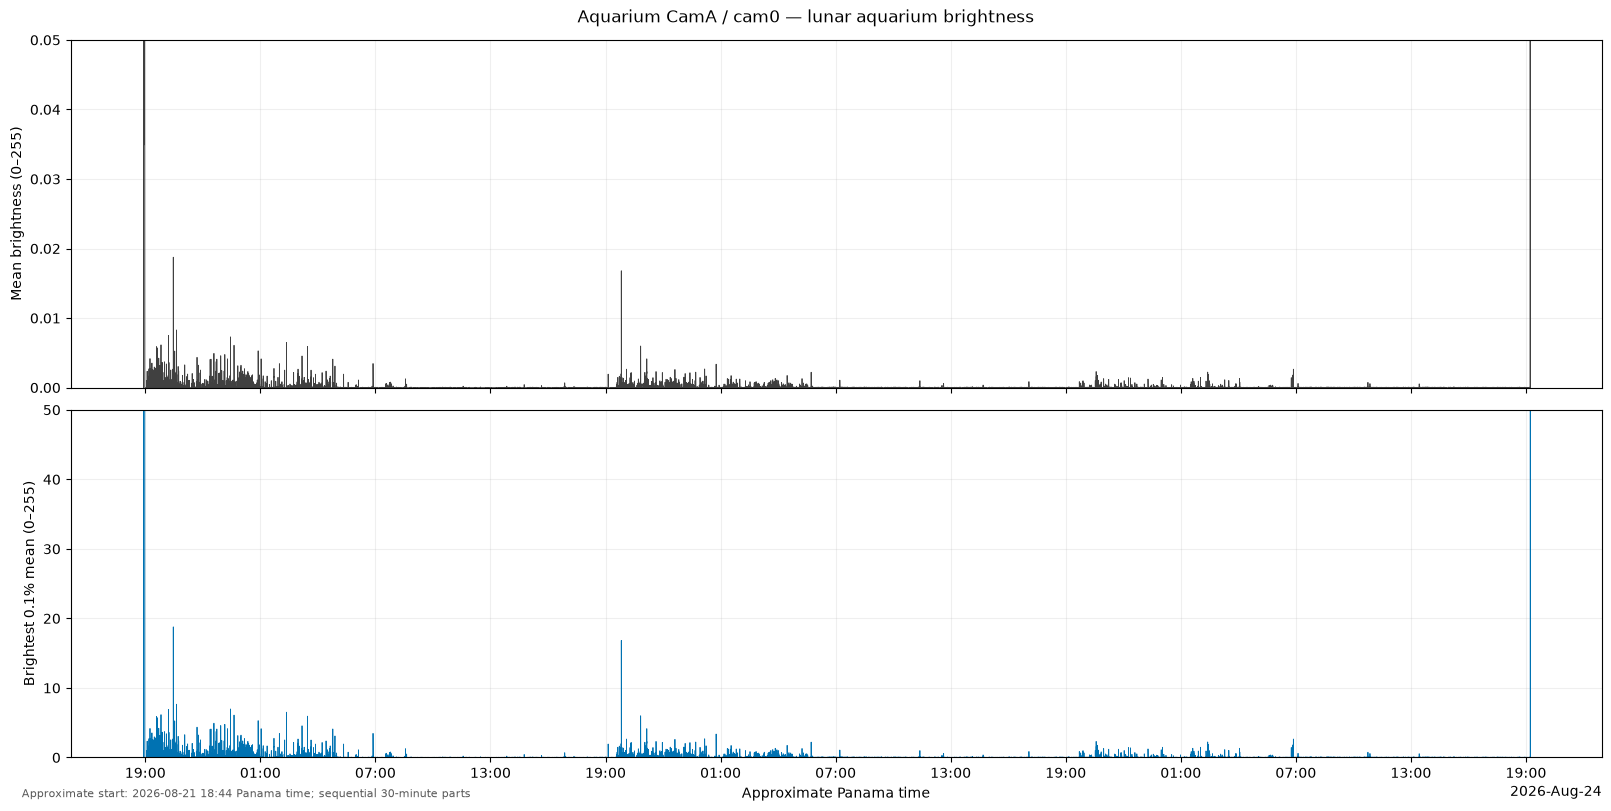

Aquarium cam1: 522,657 measurements from 146 videos


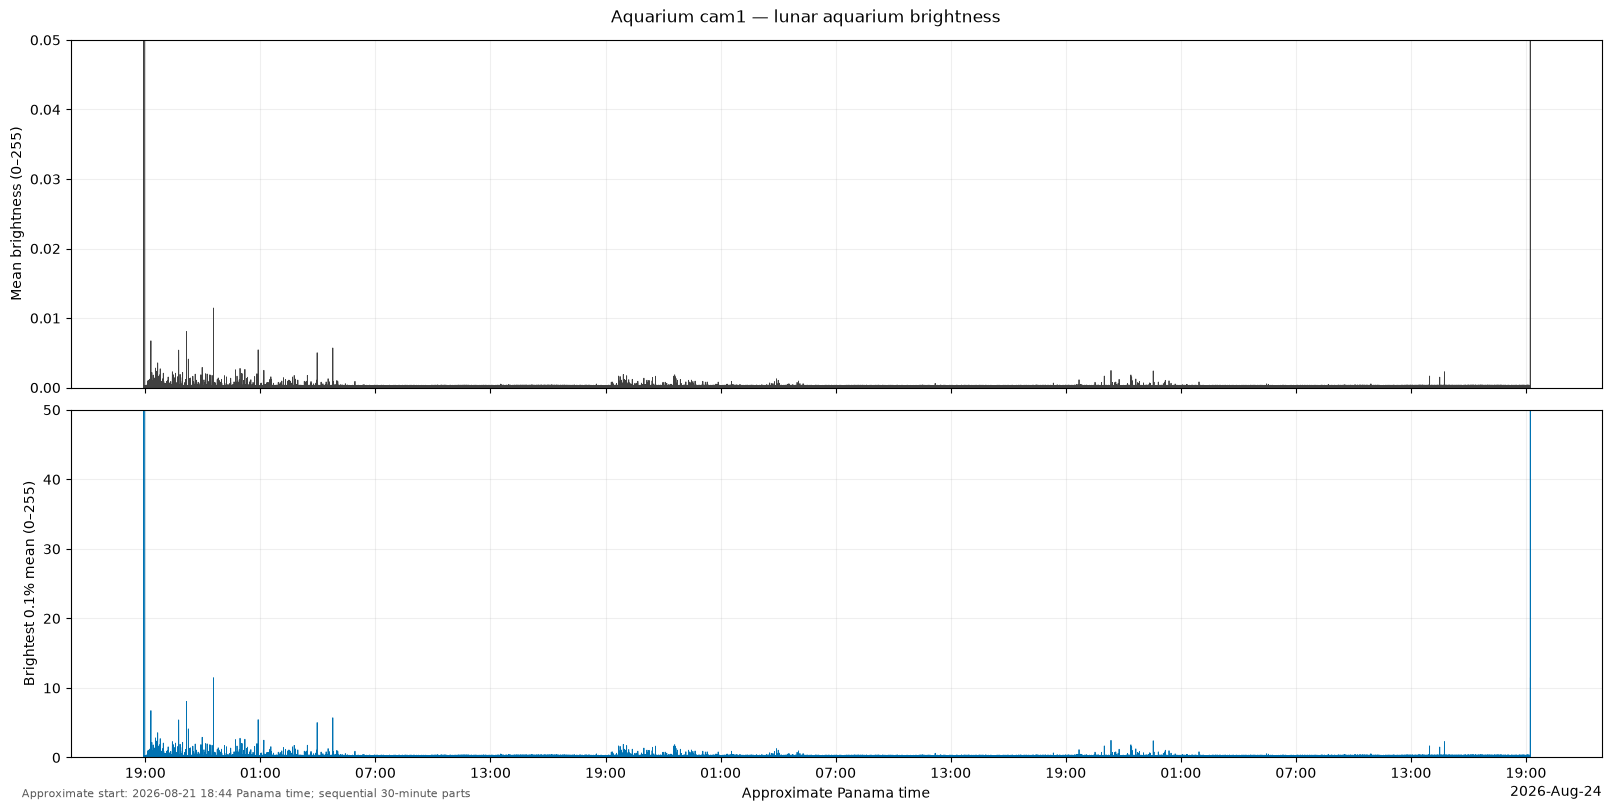

In [10]:
plot_results = {}
for dataset_key, run in dataset_runs.items():
    result_files = sorted(
        run["results_dir"].glob("*_brightness.csv"),
        key=lambda path: parse_part_number(path.name),
    )
    if not result_files:
        print(f"No completed results for {run['config']['label']}; skipping plot.")
        continue
    results = pd.concat((pd.read_csv(path) for path in result_files), ignore_index=True)
    results["time_panama"] = (
        pd.to_datetime(results["time_utc"], format="mixed", utc=True).dt.tz_convert(TIMEZONE)
    )
    results = results.sort_values("time_panama").reset_index(drop=True)
    plot_results[dataset_key] = results
    print(f"{run['config']['label']}: {len(results):,} measurements from {len(result_files)} videos")

    fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True, constrained_layout=True)
    axes[0].plot(results["time_panama"], results["mean_brightness"], lw=0.6, color="0.25")
    axes[1].plot(results["time_panama"], results["top_fraction_mean"], lw=0.6, color="#0072B2")
    axes[0].set_ylabel("Mean brightness (0–255)")
    axes[1].set_ylabel("Brightest 0.1% mean (0–255)")
    axes[1].set_xlabel("Approximate Panama time")
    if MEAN_Y_AXIS_MAX is not None:
        axes[0].set_ylim(0, MEAN_Y_AXIS_MAX)
    if BRIGHT_Y_AXIS_MAX is not None:
        axes[1].set_ylim(0, BRIGHT_Y_AXIS_MAX)
    for axis in axes:
        axis.grid(alpha=0.2)
    locator = mdates.AutoDateLocator(minticks=6, maxticks=16)
    axes[1].xaxis.set_major_locator(locator)
    axes[1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator, tz=local_zone))
    fig.suptitle(run["config"]["label"] + " — lunar aquarium brightness")
    fig.text(0.01, 0.01, "Approximate start: 2026-08-21 18:44 Panama time; sequential 30-minute parts",
             fontsize=8, color="0.35")
    plt.show()